In [2]:
import pathlib
import numpy as np
import scipy as sp
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches
import matplotlib.colors
import skimage.exposure
import harmonica as hm
import verde as vd
import choclo
import numba


import sys
sys.path.append("..")

import multipoles as mt
import micromag as mg
from micromag import MICROMETER_TO_METER, TESLA_TO_NANOTESLA

In [28]:
################################################ FORWARD 0CTUPOLE ###########################################################
# QUADRUPOLE UPWARD
def quadrupole_bz(coordinates, dipole_coordinates, dipole_moments, d_vector):
    d_vector = np.asarray(d_vector) * MICROMETER_TO_METER
    # Save the data coordinate shape so we can reshape the bz afterwards
    data_shape = coordinates[0].shape
    # Make sure coordinates are 1D arrays and the dipole moment is 2D also
    # convert all units to SI
    coordinates = [np.asarray(c).ravel() * MICROMETER_TO_METER for c in coordinates]
    dipole_coordinates = [
        np.asarray(c).ravel() * MICROMETER_TO_METER for c in dipole_coordinates
    ]
    dipole_moments = np.asarray(dipole_moments)
    if dipole_moments.ndim == 1:
        dipole_moments = np.array([dipole_moments])
    # Initialize and allocate the output array for bz
    bz = np.zeros(coordinates[0].shape)
    _quadrupole_bu_fast(
        coordinates[0],
        coordinates[1],
        coordinates[2],
        dipole_coordinates[0],
        dipole_coordinates[1],
        dipole_coordinates[2],
        dipole_moments,
        d_vector,
        bz,
    )
    bz *= TESLA_TO_NANOTESLA
    return bz.reshape(data_shape)


@numba.jit(nopython=True, parallel=True)
def _quadrupole_bu_fast(e, n, u, de, dn, du, dipole_moments, d_vector, bu):
    """
    This is the bit that runs the fast for-loops
    """
    for i in numba.prange(e.size):
        for j in range(de.size):
            result = quadrupole_magnetic_u(
                easting_p=e[i],
                northing_p=n[i],
                upward_p=u[i],
                easting_q=de[j],
                northing_q=dn[j],
                upward_q=du[j],
                magnetic_moment=dipole_moments[j, :],
                d=d_vector[j]
            )
            bu[i] += result


@numba.jit(nopython=True)   
def quadrupole_magnetic_u(
    easting_p, northing_p, upward_p, easting_q, northing_q, upward_q, magnetic_moment, d):
    
    dx, dy, dz = d[0], d[1], d[2]
    magnetic_moment_x, magnetic_moment_y, magnetic_moment_z = magnetic_moment[0], magnetic_moment[1], magnetic_moment[2]    

    distance = choclo.utils.distance_cartesian(
    easting_p,
    northing_p,
    upward_p,
    easting_q,
    northing_q,
    upward_q,
        )

    eeu = (    3 * (upward_p - upward_q) / distance**5 
            - 15 * (easting_p - easting_q)**2 * (upward_p - upward_q) / distance**7)
    
    enu = ( - 15 * (easting_p - easting_q) * (northing_p - northing_q) * (upward_p - upward_q) / distance**7 )
    
    euu = (    3 * (easting_p - easting_q) / distance**5
           - 15 * (easting_p - easting_q) * (upward_p - upward_q)**2  / distance**7)

    
    nnu = (    3 * (upward_p - upward_q) / distance**5 
            - 15 * (northing_p - northing_q)**2 * (upward_p - upward_q) / distance**7)
    
    nuu = (    3 * (northing_p - northing_q) / distance**5 
            - 15 * (northing_p - northing_q) * (upward_p - upward_q)**2 / distance**7)
    
    uuu = ( 9 * (upward_p - upward_q) / distance**5 - 15 * (upward_p - upward_q)**3 / distance**7 )
    
    result =( 
                dx*( magnetic_moment_x * eeu + magnetic_moment_y * enu + magnetic_moment_z * euu)
        +       dy*( magnetic_moment_x * enu + magnetic_moment_y * nnu + magnetic_moment_z * nuu)
        +       dz*( magnetic_moment_x * euu + magnetic_moment_y * nuu + magnetic_moment_z * uuu)
    )
                 
    
    return choclo.constants.VACUUM_MAGNETIC_PERMEABILITY / 4 / np.pi * -result




# 0CTUPOLE UPWARD
def octupole_bz(coordinates, dipole_coordinates, dipole_moments, d_vector, s_vector):
    d_vector = np.asarray(d_vector) * MICROMETER_TO_METER
    s_vector = np.asarray(s_vector) * MICROMETER_TO_METER


    # Save the data coordinate shape so we can reshape the bz afterwards
    data_shape = coordinates[0].shape
    # Make sure coordinates are 1D arrays and the dipole moment is 2D also
    # convert all units to SI
    coordinates = [np.asarray(c).ravel() * MICROMETER_TO_METER for c in coordinates]
    dipole_coordinates = [
        np.asarray(c).ravel() * MICROMETER_TO_METER for c in dipole_coordinates
    ]
    dipole_moments = np.asarray(dipole_moments)
    if dipole_moments.ndim == 1:
        dipole_moments = np.array([dipole_moments])
    # Initialize and allocate the output array for bz
    bz = np.zeros(coordinates[0].shape)
    _octupole_bu_fast(
        coordinates[0],
        coordinates[1],
        coordinates[2],
        dipole_coordinates[0],
        dipole_coordinates[1],
        dipole_coordinates[2],
        dipole_moments,
        d_vector,
        s_vector,
        bz,
    )
    bz *= TESLA_TO_NANOTESLA
    return bz.reshape(data_shape)


@numba.jit(nopython=True, parallel=True)
def _octupole_bu_fast(e, n, u, de, dn, du, dipole_moments, d_vector, s_vector, bu):
    """
    This is the bit that runs the fast for-loops
    """
    for i in numba.prange(e.size):
        for j in range(de.size):
            result = octupole_magnetic_u(
                easting_p=e[i],
                northing_p=n[i],
                upward_p=u[i],
                easting_q=de[j],
                northing_q=dn[j],
                upward_q=du[j],
                magnetic_moment=dipole_moments[j, :],
                d=d_vector[j],
                s=s_vector[j]
            )
            bu[i] += result



######
@numba.jit(nopython=True)
def octupole_magnetic_u(
    easting_p, northing_p, upward_p, easting_q, northing_q, upward_q, magnetic_moment, d, s):

    dx, dy, dz = d[0], d[1], d[2]
    sx, sy, sz = d[0], d[1], d[2]
    magnetic_moment_x, magnetic_moment_y, magnetic_moment_z = magnetic_moment[0], magnetic_moment[1], magnetic_moment[2]    

    
    distance = choclo.utils.distance_cartesian(
    easting_p,
    northing_p,
    upward_p,
    easting_q,
    northing_q,
    upward_q,
        )

    eeuu = (3 / distance**5
        - 15 * (upward_p - upward_q)**2 / distance**7
        - 15 * (easting_p - easting_q)**2 / distance**7
        + 105 * (easting_p - easting_q)**2 * (upward_p - upward_q)**2 / distance**9)
    enuu = ( 105 * (easting_p - easting_q) * (northing_p - northing_q) * (upward_p - upward_q)**2 / distance**9
                - 15 * (easting_p - easting_q) * (northing_p - northing_q) / distance**7)
    euuu = ( 105 * (easting_p - easting_q) * (upward_p - upward_q)**3 / distance**9
                - 45 * (easting_p - easting_q) * (upward_p - upward_q) / distance**7)
    nnuu = ( 3/distance**5
                - 15 * (upward_p - upward_q)**2 / distance**7
                - 15 * (northing_p - northing_q)**2 / distance**7
                + 105 * (northing_p - northing_q)**2 * (upward_p - upward_q)**2 / distance**9)
    nuuu = ( 105 * (northing_p - northing_q) * (upward_p - upward_q)**3 / distance**9
                - 45 * (northing_p - northing_q) * (upward_p - upward_q) / distance**7)
    uuuu = ( 9 / distance**5
                - 90 * (upward_p - upward_q)**2 / distance**7
                + 105 * (upward_p - upward_q)**4 / distance**9)
    
    eeeu = (105 * (easting_p - easting_q)**3 * (upward_p - upward_q) / distance**9
            - 45 * (easting_p - easting_q) * (upward_p - upward_q) / distance**7)
    eneu = (105 * (northing_p - northing_q) * (upward_p - upward_q) * (easting_p - easting_q)**2 / distance**9
                - 15 * (northing_p - northing_q) * (upward_p - upward_q) / distance**7)
    eueu = eeuu
    nneu = (105 * (northing_p - northing_q)**2 * (upward_p - upward_q) * (easting_p - easting_q) / distance**9
                - 15 * (upward_p - upward_q) * (easting_p - easting_q) / distance**7)
    nueu = enuu
    uueu = euuu 
    eenu = eneu
    ennu = nneu
    eunu = enuu
    nnnu = (105 * (northing_p - northing_q)**3 * (upward_p - upward_q) / distance**9
                - 45 * (northing_p - northing_q) * (upward_p - upward_q) / distance**7)
    nunu = nnuu
    uunu = nuuu
    

    Bz_quad_z =( 
                dx*( magnetic_moment_x * eeuu + magnetic_moment_y * enuu + magnetic_moment_z * euuu)
        +       dy*( magnetic_moment_x * enuu + magnetic_moment_y * nnuu + magnetic_moment_z * nuuu)
        +       dz*( magnetic_moment_x * euuu + magnetic_moment_y * nuuu + magnetic_moment_z * uuuu)
    )  
    Bx_quad_z =( 
                dx*( magnetic_moment_x * eeeu + magnetic_moment_y * eneu + magnetic_moment_z * eueu)
        +       dy*( magnetic_moment_x * eneu + magnetic_moment_y * nneu + magnetic_moment_z * nueu)
        +       dz*( magnetic_moment_x * eueu + magnetic_moment_y * nueu + magnetic_moment_z * uueu)
    )
    By_quad_z =( 
                dx*( magnetic_moment_x * eenu + magnetic_moment_y * ennu + magnetic_moment_z * eunu)
        +       dy*( magnetic_moment_x * ennu + magnetic_moment_y * nnnu + magnetic_moment_z * nunu)
        +       dz*( magnetic_moment_x * eunu + magnetic_moment_y * nunu + magnetic_moment_z * uunu)
    )
       
    result = (sx*Bx_quad_z + sy*By_quad_z + sz*Bz_quad_z)
    
    return choclo.constants.VACUUM_MAGNETIC_PERMEABILITY / 4 / np.pi * -result


In [29]:
def angular_distance(vec_a, vec_b):
    dot_product = np.dot(vec_a, vec_b)
    
    magnitude_a = np.linalg.norm(vec_a)
    magnitude_b = np.linalg.norm(vec_b)
    
    cos_theta = dot_product / (magnitude_a * magnitude_b)
    
    theta = np.rad2deg(np.arccos(cos_theta))
    theta = np.arccos(np.clip(cos_theta, -1.0, 1.0))
    return theta

def goal_function_dipole(parameter, obs_data, coordinates, amplitude, x_0, y_0, z_0):
    bz = mg.dipole_bz(coordinates, 
                      ([parameter[0]*x_0], [parameter[1]*y_0], [parameter[2]*z_0]),
                     np.array([parameter[3], parameter[4], parameter[5]])*amplitude
                     )
    
    Res = np.linalg.norm(obs_data-bz.ravel())
    return(Res)

In [36]:
# grid parameters
bound = 1
spacing = bound / 25
sensor_sample_distance = 0.5  # µm

coordinates = vd.grid_coordinates(
    region=[-bound, bound, -bound, bound],  # µm
    spacing=spacing,
    extra_coords=sensor_sample_distance,
)

In [37]:
np.random.seed(5)

dipole_coordinates = (
    (0),  # µm
    (0),  # µm
    (0),  # µm
)
dipole_moments = mg.angles_to_vector(
    inclination=(0),
    declination=(0),
    amplitude=(5e-16),
)

In [53]:
# bz_regional = mg.dipole_bz(coordinates, deep_dipole_coordinates, deep_dipole_moments)
bz = mg.dipole_bz(coordinates, dipole_coordinates, dipole_moments)

d_vector = np.array([[0.0, 0.5, 0.0]])  # em µm
d_vector_octu = np.array([[0.4, 0.0, 0.0]]) 
s_vector = np.array([[0.3, 0.0, 0.0]])  # em µm



bz_quad = quadrupole_bz(coordinates, dipole_coordinates, dipole_moments, d_vector)
bz_octu = octupole_bz(coordinates, dipole_coordinates, dipole_moments, d_vector_octu, s_vector)

data = vd.make_xarray_grid(coordinates, bz+bz_quad+bz_octu, data_names=["bz"], dims=("y", "x"), extra_coords_names="z")
data.x.attrs = {"units": "µm"}
data.y.attrs = {"units": "µm"}
data.bz.attrs = {"long_name": "vertical magnetic field", "units": "nT"}

noise_std_dev = 50# nT
data.bz.values += mg.gaussian_noise(noise_std_dev, data.bz.shape, seed=42)


height_difference = 1.0e-20

data = (
    hm.upward_continuation(data.bz, height_difference)
    .assign_attrs(data.bz.attrs)
    .to_dataset(name="bz")
    .assign_coords(x=data.x, y=data.y)
    .assign_coords(z=data.z + height_difference)
)

data = data.assign(mg.data_gradients(data.bz))

data

<xarray.Dataset> Size: 126kB
Dimensions:  (y: 51, x: 51)
Coordinates:
  * x        (x) float64 408B -1.0 -0.96 -0.92 -0.88 ... 0.88 0.92 0.96 1.0
  * y        (y) float64 408B -1.0 -0.96 -0.92 -0.88 ... 0.88 0.92 0.96 1.0
    z        (y, x) float64 21kB 0.5 0.5 0.5 0.5 0.5 0.5 ... 0.5 0.5 0.5 0.5 0.5
Data variables:
    bz       (y, x) float64 21kB 3.588e+03 4.019e+03 ... 1.004e+04 8.472e+03
    tga      (y, x) float64 21kB 2.554e+05 2.97e+05 ... 2.829e+05 1.686e+05
    x_deriv  (y, x) float64 21kB 1.078e+04 1.299e+04 ... -3.96e+04 -3.914e+04
    y_deriv  (y, x) float64 21kB 1.559e+04 1.737e+04 ... 1.741e+04 1.295e+04
    z_deriv  (y, x) float64 21kB 2.547e+05 2.962e+05 ... -2.796e+05 -1.634e+05

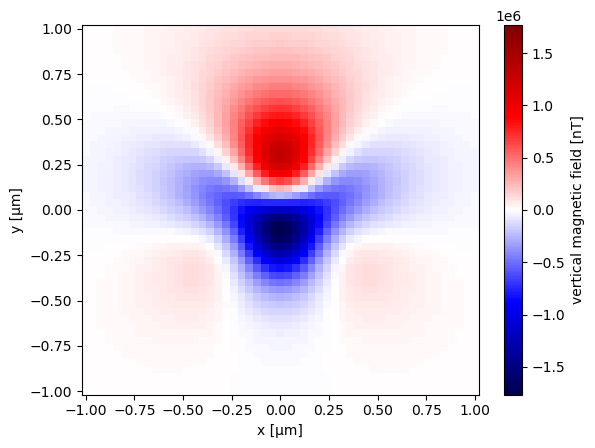

In [54]:
data.bz.plot.pcolormesh(cmap="seismic")#, vmax=5000, vmin=-5000)

## Dipole Linear

In [55]:
position, base_level = mg.euler_deconvolution(
    data.bz, data.x_deriv, data.y_deriv, data.z_deriv
)
data_minus_background = data.bz.values - base_level
data = data.assign(data_minus_background=(['y','x'], data_minus_background))
moment_dip_lin, *_ = mg.dipole_moment_inversion(data.data_minus_background, position)
angular_dip_lin = angular_distance(dipole_moments, moment_dip_lin)
_, _, amp_real = mg.vector_to_angles(dipole_moments)
_, _, amp_model = mg.vector_to_angles(moment_dip_lin)
moment_dip_misfit_lin = abs((amp_real - amp_model) / amp_real) * 100
pos_dip_misfit_lin = np.linalg.norm(np.array(dipole_coordinates) - np.array(position))


# # plot results for linear dipolar model
pred_dip_lin = mg.dipole_bz([coordinates[0], coordinates[1], data.z], position, moment_dip_lin)    
data = data.assign(pred_dip_lin=(['y','x'],pred_dip_lin))
data.pred_dip_lin.attrs = {"long_name": "predicted-data", "units": "nT"}
residual_dip_lin = data.bz.values - data.pred_dip_lin.values
data = data.assign(residual_dip_lin=(['y','x'],residual_dip_lin))
data.residual_dip_lin.attrs = {"long_name": "residual-data", "units": "nT"}

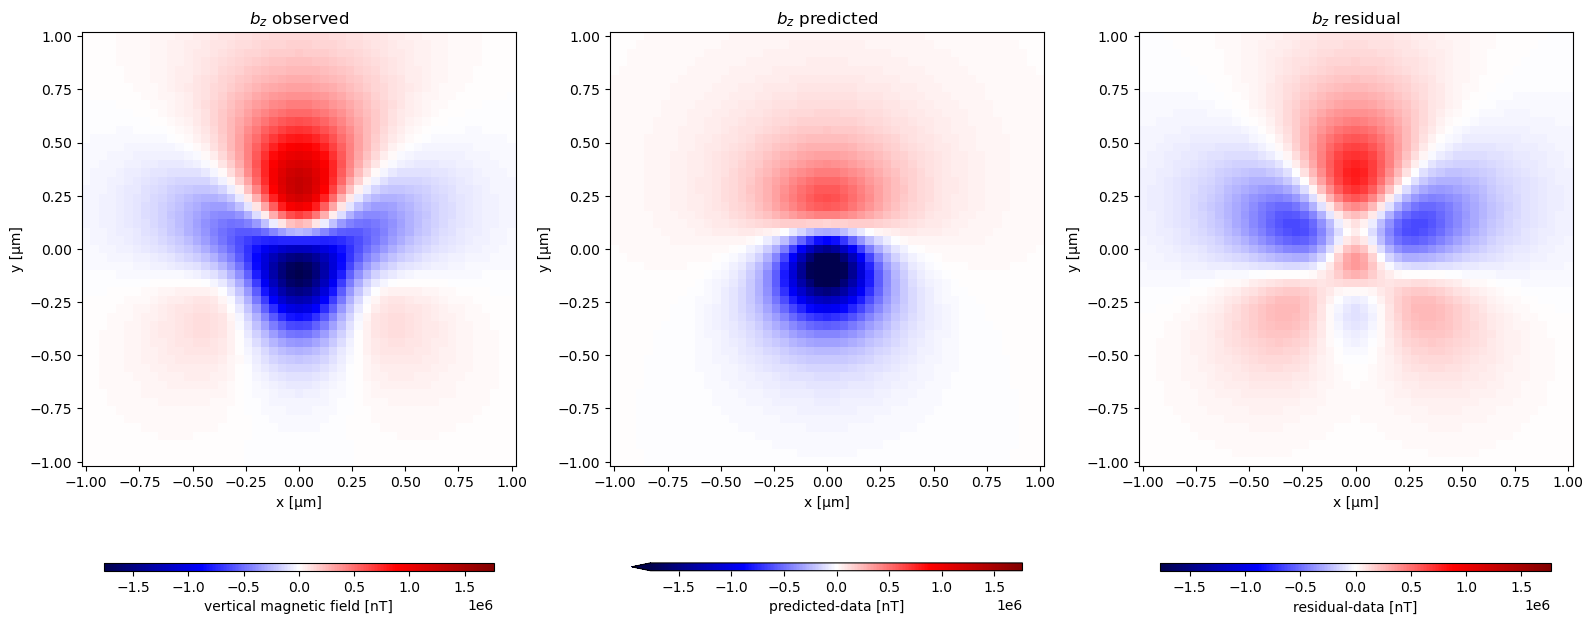

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(16, 10))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
scale = vd.maxabs(data.bz)
vmax =  scale
vmin = -scale #data['bz_total'].values.min()
for field, ax in zip(["bz", "pred_dip_lin", "residual_dip_lin"], axes.ravel()):

    data[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
for ax, title in zip(axes.ravel(), [r'$b_z$ observed', r'$b_z$ predicted', r'$b_z$ residual']):
    ax.set_aspect("equal")
    ax.set_title(title)

plt.tight_layout()

## Dipole Nonlinear

In [57]:
### DIPOLAR NONLINEAR ###
##################################################################################
table = vd.grid_to_table(data)
amp = np.linalg.norm(moment_dip_lin)
args = (table.bz.values.ravel(), (table.x.values, table.y.values, table.z.values.ravel()), amp, *position)
opt = sp.optimize.minimize(goal_function_dipole, (1, 1, 1, *(moment_dip_lin / amp)), args=args, method="Nelder-Mead")
if opt.success:
    moment_dip_nonlin = np.array(opt.x[3:]) * amp
    pos_dip_nonlin = np.array(opt.x[:3]) * np.array(position)
else:
    moment_dip_nonlin = moment_dip_lin
    pos_dip_nonlin = position
ang_dip_nonlin = angular_distance(dipole_moments, moment_dip_nonlin)
_, _, amp_model = mg.vector_to_angles(moment_dip_nonlin)
mom_dip_misfit_nonlin = abs((amp_real - amp_model) / amp_real) * 100
pos_dip_misfit_nonlin = np.linalg.norm(np.array(dipole_coordinates) - pos_dip_nonlin)

# # plot results for nonlinear dipolar model
pred_dip_nonlin = mg.dipole_bz([coordinates[0], coordinates[1], data.z], pos_dip_nonlin, moment_dip_nonlin)    
data = data.assign(pred_dip_nonlin=(['y','x'],pred_dip_nonlin))
data.pred_dip_nonlin.attrs = {"long_name": "predicted-data", "units": "nT"}
residual_dip_nonlin = data.bz.values - data.pred_dip_nonlin.values
data = data.assign(residual_dip_nonlin=(['y','x'],residual_dip_nonlin))
data.residual_dip_nonlin.attrs = {"long_name": "residual-data", "units": "nT"}


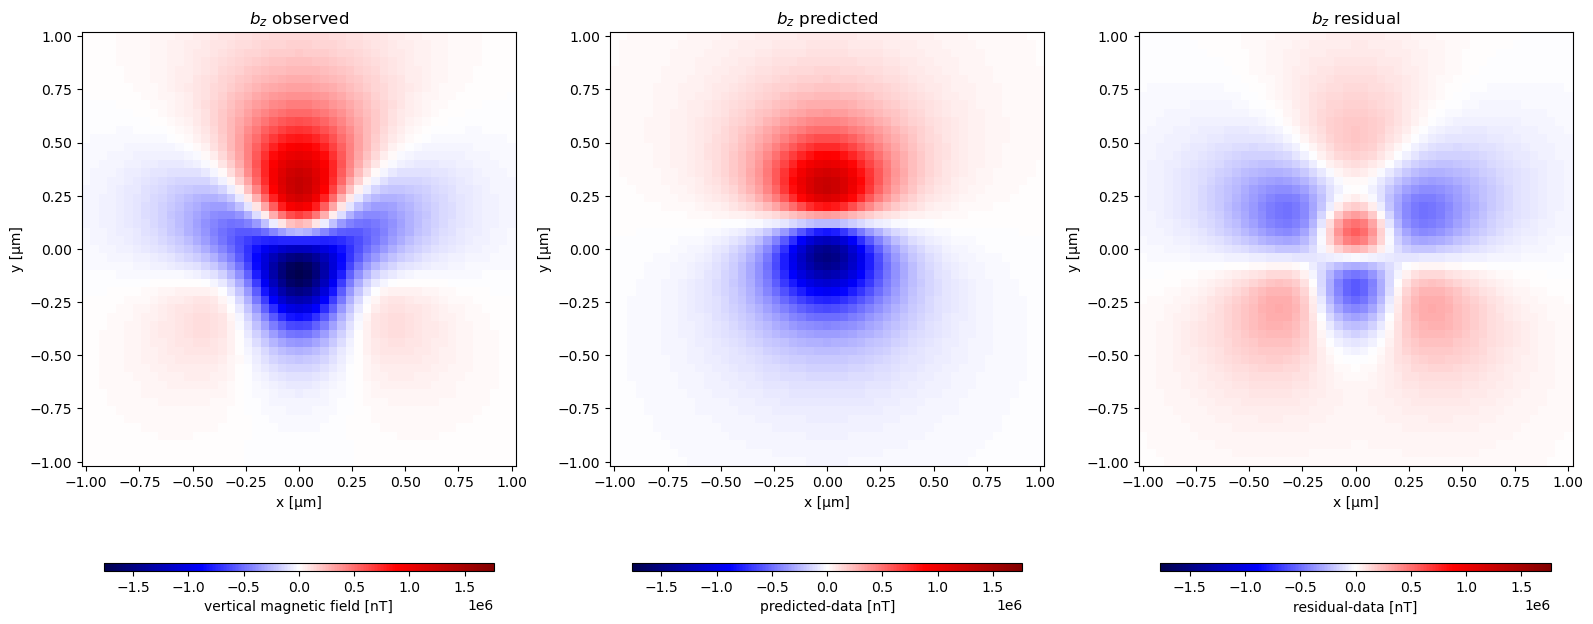

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(16, 10))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
vmax =  scale
vmin = -scale #data['bz_total'].values.min()
for field, ax in zip(["bz", "pred_dip_nonlin", "residual_dip_nonlin"], axes.ravel()):

    data[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
for ax, title in zip(axes.ravel(), [r'$b_z$ observed', r'$b_z$ predicted', r'$b_z$ residual']):
    ax.set_aspect("equal")
    ax.set_title(title)

plt.tight_layout()

## Spherical Harmonics

In [59]:
##################################################################################
### SPHERICAL HARMONIC ###

sph = mt.SphericalHarmonicsBz(pos_dip_nonlin, min_degree=1, max_degree=6).fit(coordinates, data.data_minus_background)
pred_shp = sph.predict(coordinates)
moment_shp = sph.magnetic_moment_
pos_mp_lin = sph.location

ang_mp_lin = angular_distance(dipole_moments, moment_shp)
_, _, amp_model = mg.vector_to_angles(moment_shp)
mom_mp_misfit_lin = abs((amp_real - amp_model) / amp_real) * 100
pos_mp_misfit_lin = np.linalg.norm(np.array(dipole_coordinates) - pos_mp_lin)

# # plot results for linear multipolar model
data = data.assign(pred_shp=(['y','x'],np.reshape(pred_shp, data.bz.shape)))
data.pred_shp.attrs = {"long_name": "predicted-data", "units": "nT"}
residual_mp_lin = data.bz.values - data.pred_shp.values
data = data.assign(residual_mp_lin=(['y','x'],residual_mp_lin))
data.residual_mp_lin.attrs = {"long_name": "residual-data", "units": "nT"}

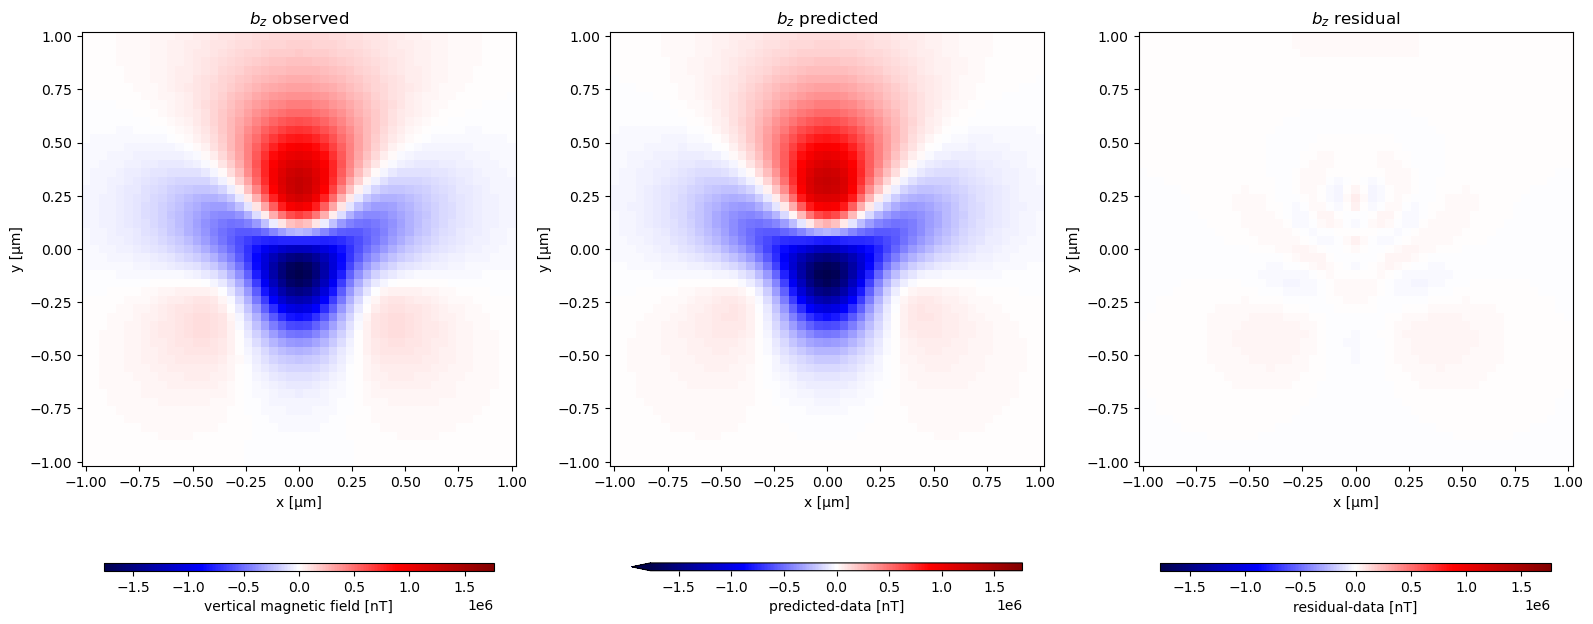

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(16, 10))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
vmax =  scale
vmin = -scale #data['bz_total'].values.min()
for field, ax in zip(["bz", "pred_shp", "residual_mp_lin"], axes.ravel()):

    data[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
for ax, title in zip(axes.ravel(), [r'$b_z$ observed', r'$b_z$ predicted', r'$b_z$ residual']):
    ax.set_aspect("equal")
    ax.set_title(title)

plt.tight_layout()

## Spherical Harmonic Nonlinear

In [61]:
#########################################################################################################
### SPHERICAL HARMONIC WITH NONLINEAR POSITION ESTIMATION ###
sph.update_location(coordinates, table)
pred_shp_nl  = sph.predict(coordinates)
moment_shp_nl = sph.magnetic_moment_
pos_mp_nonlin = sph.location

ang_mp_nonlin = angular_distance(dipole_moments, moment_shp_nl)
_, _, model_amp = mg.vector_to_angles(moment_shp_nl)
mom_mp_misfit_nonlin = np.abs((amp_real - model_amp) / amp_real) * 100
pos_mp_misfit_nonlin = np.linalg.norm(np.array(dipole_coordinates) - pos_mp_nonlin)

# # plot results for non-linear multipolar model
data = data.assign(pred_shp_nl=(['y','x'],np.reshape(pred_shp_nl, data.bz.shape)))
data.pred_shp_nl.attrs = {"long_name": "predicted-data", "units": "nT"}
residual_mp_nonlin = data.bz.values - data.pred_shp_nl.values
data = data.assign(residual_mp_nonlin=(['y','x'],residual_mp_nonlin))
data.residual_mp_nonlin.attrs = {"long_name": "residual-data", "units": "nT"}

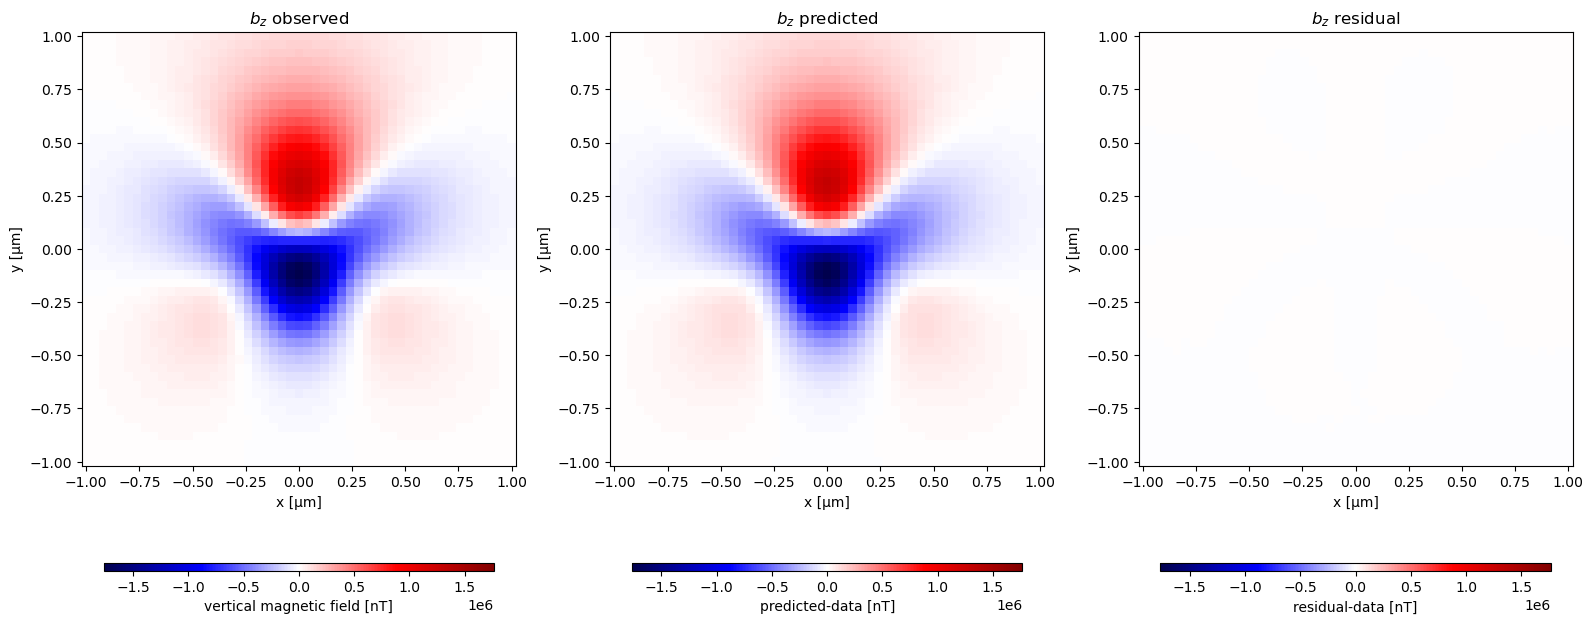

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(16, 10))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
vmax =  scale
vmin = -scale #data['bz_total'].values.min()
for field, ax in zip(["bz", "pred_shp_nl", "residual_mp_nonlin"], axes.ravel()):

    data[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
for ax, title in zip(axes.ravel(), [r'$b_z$ observed', r'$b_z$ predicted', r'$b_z$ residual']):
    ax.set_aspect("equal")
    ax.set_title(title)

plt.tight_layout()

In [63]:
inc, dec, amp = mg.vector_to_angles(dipole_moments)
print("Real dipole moments:")
print(f"   Inclination: {inc:.2f}°")
print(f"   Declination: {dec:.2f}°")
print(f"   Amplitude: {amp:.2e}")
print(f"   Position: ({dipole_coordinates[0]:.3e},{dipole_coordinates[1]:.3e},{dipole_coordinates[2]:.3e})")
print()

inc, dec, amp = mg.vector_to_angles(moment_dip_lin)
print("→ Dipole approximation obtained by fitting a linear dipole model:")
print(f"   Inclination: {inc:.2f}°")
print(f"   Declination: {dec:.2f}°")
print(f"   Amplitude: {amp:.2e}")
print(f"   Position: ({position[0]:.3e},{position[1]:.3e},{position[2]:.3e})")
print()

inc, dec, amp = mg.vector_to_angles(moment_dip_nonlin)
print("→ Dipole approximation obtained by fitting a nonlinear dipole model:")
print(f"   Inclination: {inc:.2f}°")
print(f"   Declination: {dec:.2f}°")
print(f"   Amplitude: {amp:.2e}")
print(f"   Position: ({pos_dip_nonlin[0]:.3e},{pos_dip_nonlin[1]:.3e},{pos_dip_nonlin[2]:.3e})")
print()

inc, dec, amp = mg.vector_to_angles(moment_shp)
print("→ Dipole component estimated from the spherical harmonic model:")
print(f"   Inclination: {inc:.2f}°")
print(f"   Declination: {dec:.2f}°")
print(f"   Amplitude: {amp:.2e}")
print(f"   Position: ({pos_mp_lin[0]:.3e},{pos_mp_lin[1]:.3e},{pos_mp_lin[2]:.3e})")
print()

inc, dec, amp = mg.vector_to_angles(moment_shp_nl)
print("→ Dipole component estimated from the nonlinear spherical harmonic model:")
print(f"   Inclination: {inc:.2f}°")
print(f"   Declination: {dec:.2f}°")
print(f"   Amplitude: {amp:.2e}")
print(f"   Position: ({pos_mp_nonlin[0]:.3e},{pos_mp_nonlin[1]:.3e},{pos_mp_nonlin[2]:.3e})")


Real dipole moments:
   Inclination: 0.00°
   Declination: 0.00°
   Amplitude: 5.00e-16
   Position: (0.000e+00,0.000e+00,0.000e+00)

→ Dipole approximation obtained by fitting a linear dipole model:
   Inclination: 29.94°
   Declination: 0.00°
   Amplitude: 4.06e-16
   Position: (8.890e-07,-2.818e-03,1.995e-01)

→ Dipole approximation obtained by fitting a nonlinear dipole model:
   Inclination: 4.11°
   Declination: 0.00°
   Amplitude: 5.93e-16
   Position: (-3.057e-06,1.209e-01,1.687e-01)

→ Dipole component estimated from the spherical harmonic model:
   Inclination: 17.40°
   Declination: 0.00°
   Amplitude: 3.21e-16
   Position: (-3.057e-06,1.209e-01,1.687e-01)

→ Dipole component estimated from the nonlinear spherical harmonic model:
   Inclination: -0.17°
   Declination: 0.01°
   Amplitude: 4.74e-16
   Position: (-3.057e-06,1.209e-01,-2.847e-02)
